# 03a: Preprocessing experiments
Imputation (mean vs median, missingness indicators), PCA, and feature-set comparison.
All preprocessing is fitted on training data only, inside scikit-learn pipelines.

In [1]:
import sys; sys.path.append("../src")
from common import *

df, X, y = load_data()
(X_train, X_val, X_test, y_train, y_val, y_test,
 X_trval, y_trval, id_train, id_val, id_test) = split_data(X, y, df["country"])
print(len(X_train), len(X_val), len(X_test))
print(np.bincount(y_train), np.bincount(y_val), np.bincount(y_test))
pre = make_preprocessor().fit(X_train)
print(pre.get_feature_names_out())

115 39 39
[16 55 44] [ 5 19 15] [ 5 19 15]
['skewed__inflation' 'skewed__trade_gdp' 'num__gdp_growth'
 'num__unemployment' 'num__infant_mortality' 'num__electricity_access'
 'num__internet_users' 'num__agriculture_gdp' 'num__industry_gdp'
 'cat__region_East Asia & Pacific' 'cat__region_Europe & Central Asia'
 'cat__region_Latin America & Caribbean'
 'cat__region_Middle East, North Africa, Afghanistan & Pakistan'
 'cat__region_North America' 'cat__region_South Asia'
 'cat__region_Sub-Saharan Africa' 'cat__DominantSector_Agriculture'
 'cat__DominantSector_Industry' 'cat__DominantSector_Missing'
 'cat__DominantSector_Services']


## 1. Imputation: mean vs median, with and without missingness indicators
Compared with 5-fold stratified cross-validation on the training set (macro F1), for logistic regression and random forest.

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "logistic regression": LogisticRegression(max_iter=5000),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
}

rows = []
for mname, model in models.items():
    for impute in ["mean", "median"]:
        for ind in [False, True]:
            pipe = Pipeline([("pre", make_preprocessor(impute=impute, indicator=ind)),
                             ("clf", model)])
            s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
            rows.append({"model": mname, "imputation": impute, "missing indicators": ind,
                         "macro F1 mean": round(s.mean(), 3), "sd": round(s.std(), 3)})

imp_table = pd.DataFrame(rows)
imp_table

,model,imputation,missing indicators,macro F1 mean,sd
0,logistic regression,mean,False,0.839,0.068
1,logistic regression,mean,True,0.797,0.074
2,logistic regression,median,False,0.818,0.074
3,logistic regression,median,True,0.796,0.073
4,random forest,mean,False,0.890,0.061
5,random forest,mean,True,0.897,0.060
6,random forest,median,False,0.875,0.075
7,random forest,median,True,0.889,0.072


**Observations (imputation)**
- All differences are smaller than one CV standard deviation (≈0.06–0.07), so the imputation choice matters little here
  (at most 12% of any feature is missing).
- Logistic regression: mean imputation without indicators is best (0.839). Missingness indicators reduce it to ≈0.80,
  probably because the extra mostly-zero columns add noise for a linear model trained on only 115 countries.
- Random forest: all options lie between 0.875 and 0.897; mean with indicators is marginally best.
- **Interpretation of an indicator:** its coefficient/importance shows whether *"this value was not reported"* is itself
  associated with the class. This is plausible here, because missing values are more common in lower-HDI countries
  (see EDA), but the gain is not reliable at this sample size.
- **Decision:** mean imputation without indicators for all models (best for logistic regression, within 0.01 of the best
  for the random forest, and one shared preprocessor keeps the model comparison fair).

## 2. PCA (fitted on the preprocessed training features only)

PC1 explains 38.8 %
components needed for 90% variance: 7 of 20


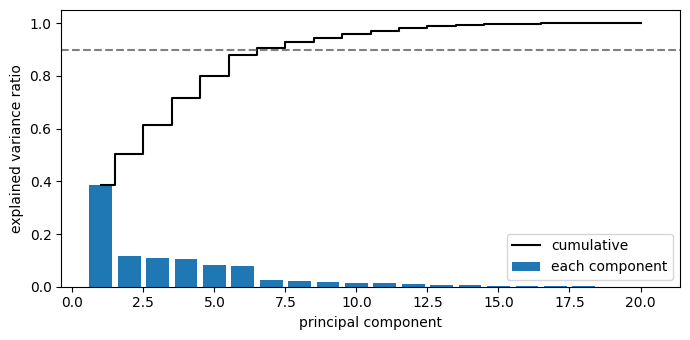

In [4]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pre = make_preprocessor().fit(X_train)          # fitted on TRAINING data only
Z_train = pre.transform(X_train)                # scaled + encoded training features
feat_names = [n.split("__")[1] for n in pre.get_feature_names_out()]

pca = PCA().fit(Z_train)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
print("PC1 explains", round(evr[0] * 100, 1), "%")
print("components needed for 90% variance:", int(np.argmax(cum >= 0.90)) + 1, "of", len(evr))

plt.figure(figsize=(7, 3.5))
plt.bar(range(1, len(evr) + 1), evr, label="each component")
plt.step(range(1, len(evr) + 1), cum, where="mid", color="black", label="cumulative")
plt.axhline(0.9, ls="--", color="grey")
plt.xlabel("principal component"); plt.ylabel("explained variance ratio"); plt.legend()
plt.tight_layout(); plt.savefig("../figures/pca_explained_variance.png", dpi=150); plt.show()

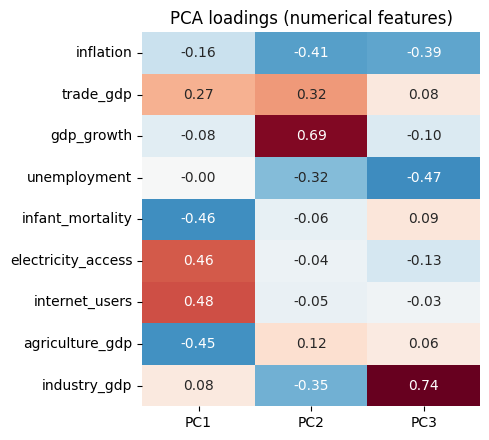

In [5]:
import seaborn as sns
loadings = pd.DataFrame(pca.components_[:3].T, index=feat_names, columns=["PC1", "PC2", "PC3"])
plt.figure(figsize=(5, 4.5))
sns.heatmap(loadings.iloc[:len(NUM)], annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False)
plt.title("PCA loadings (numerical features)"); plt.tight_layout()
plt.savefig("../figures/pca_loadings.png", dpi=150); plt.show()

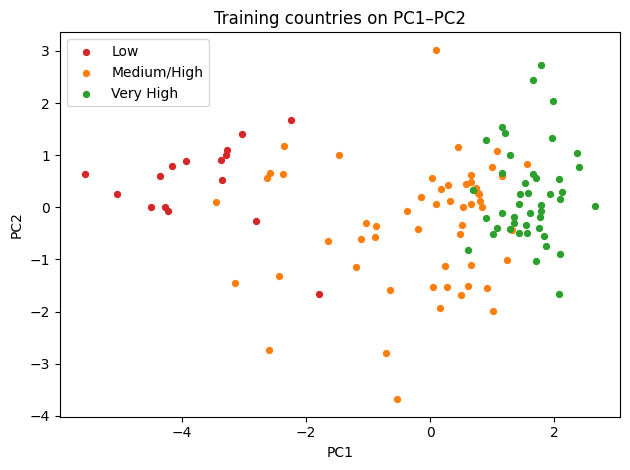

In [6]:
Z2 = pca.transform(Z_train)[:, :2]
for k, c in zip(range(3), ["tab:red", "tab:orange", "tab:green"]):
    plt.scatter(Z2[y_train == k, 0], Z2[y_train == k, 1], s=18, c=c, label=CLASS_NAMES[k])
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.title("Training countries on PC1–PC2")
plt.tight_layout(); plt.savefig("../figures/pca_scatter.png", dpi=150); plt.show()

**Observations (PCA)**
- PC1 explains 38.8% of the variance; 7 of 20 components are needed for 90%.
- **PC1 is a "development" axis:** high internet use (+0.48) and electricity access (+0.46) versus high infant
  mortality (−0.46) and agriculture share (−0.45), the strongly correlated block found in the EDA.
- PC2 captures short-run macro conditions (GDP growth +0.69, inflation −0.41, industry −0.35);
  PC3 mainly industry share (+0.74) versus unemployment (−0.47).
- On PC1–PC2 the classes are ordered along PC1: Low is clearly separated, while Medium/High overlaps Very High.
  Most class information is therefore concentrated in one dimension.

### Models with vs without PCA (5-fold stratified CV on training data)

In [7]:
rows = []
for mname, model in models.items():
    for k in [None, 2, 3, 5, 0.90]:
        steps = [("pre", make_preprocessor())]
        if k is not None:
            steps.append(("pca", PCA(n_components=k, random_state=SEED)))
        steps.append(("clf", model))
        s = cross_val_score(Pipeline(steps), X_train, y_train, cv=cv, scoring="f1_macro")
        rows.append({"model": mname,
                     "PCA": "none" if k is None else ("90% variance" if k == 0.90 else f"{k} components"),
                     "macro F1 mean": round(s.mean(), 3), "sd": round(s.std(), 3)})
pca_table = pd.DataFrame(rows)
pca_table

,model,PCA,macro F1 mean,sd
0,logistic regression,none,0.839,0.068
1,logistic regression,2 components,0.857,0.042
2,logistic regression,3 components,0.857,0.053
3,logistic regression,5 components,0.830,0.051
4,logistic regression,90% variance,0.829,0.052
5,random forest,none,0.890,0.061
6,random forest,2 components,0.821,0.031
7,random forest,3 components,0.834,0.022
8,random forest,5 components,0.868,0.049
9,random forest,90% variance,0.836,0.039


**Observations (with vs without PCA)**
- Logistic regression: keeping only 2–3 components gives a slightly higher and more stable CV macro F1
  (0.857 ± 0.04 vs 0.839 ± 0.07 without PCA). PCA removes the collinearity among the development indicators,
  which helps a linear model trained on 115 countries.
- Random forest: PCA lowers performance (0.82–0.87 vs 0.890). Trees split on individual original features
  (e.g. electricity access); rotating features into components makes such splits harder to find.
- PCA therefore retains most of the useful information in very few components (2 PCs ≈ all 20 features for
  logistic regression), confirming strong redundancy. The gain for logistic regression is within one SD, so we keep
  the final models without PCA, which also keeps them interpretable in terms of the original indicators.

## 3. Numerical-only vs categorical-only vs combined features

In [8]:
sets = {
    "numerical only":             (NUM, []),
    "categorical only":           ([], CAT),
    "numerical + region":         (NUM, ["region"]),
    "numerical + DominantSector": (NUM, ["DominantSector"]),
    "combined (all)":             (NUM, CAT),
}
rows = []
for mname, model in models.items():
    for label, (num, cat) in sets.items():
        pipe = Pipeline([("pre", make_preprocessor(num=num, cat=cat)), ("clf", model)])
        s = cross_val_score(pipe, X_train[num + cat], y_train, cv=cv, scoring="f1_macro")
        rows.append({"model": mname, "features": label,
                     "macro F1 mean": round(s.mean(), 3), "sd": round(s.std(), 3)})
fs_table = pd.DataFrame(rows)
fs_table

,model,features,macro F1 mean,sd
0,logistic regression,numerical only,0.846,0.045
1,logistic regression,categorical only,0.512,0.106
2,logistic regression,numerical + region,0.837,0.087
3,logistic regression,numerical + DominantSector,0.846,0.045
4,logistic regression,combined (all),0.839,0.068
5,random forest,numerical only,0.888,0.072
6,random forest,categorical only,0.545,0.106
7,random forest,numerical + region,0.890,0.061
8,random forest,numerical + DominantSector,0.895,0.071
9,random forest,combined (all),0.890,0.061


**Observations (feature sets)**
- Categorical only (region + DominantSector) is weak (macro F1 0.51–0.55), although clearly above the majority baseline:
  region alone carries some information (e.g. Sub-Saharan Africa ↔ Low).
- Numerical only already achieves almost the full performance (0.846 logistic regression, 0.888 random forest).
- Adding region or DominantSector changes CV macro F1 by at most ±0.01, which is within one standard deviation.
  The numerical development indicators already encode most regional differences, and DominantSector is nearly constant
  (91% "Services") and derived from the sector shares already included.
- **Conclusion:** neither region nor the engineered sector reliably improves prediction. We keep the combined set
  for the final models (it is never worse and lets us interpret region), but a numerical-only model is essentially as good.

## Summary of preprocessing decisions (used in 03b_modelling)
| Decision | Choice | Evidence |
|---|---|---|
| Imputation | mean, no missingness indicators | best for logistic regression; within 0.01 of best for the forest |
| Skewed features | sign-preserving log on inflation and trade | extreme but genuine values (EDA) |
| PCA | not used in final models | helps logistic regression slightly (within 1 SD), hurts the forest; original features more interpretable |
| Feature set | combined (numerical + region + DominantSector) | categorical adds ≤ 0.01, never hurts |